<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/Perbandingan_KMeans_DBScan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Perbandingan 9 Konfigurasi (3 Algoritma x 3 Metrik) - Dataset PBL

Semua konfigurasi dijalankan pada **data yang sama** (15.000 sampel, preprocessing identik)
dengan **jumlah cluster yang sama (k=3)** agar perbandingan **fair**.

Notebook ini merangkum hasil dari 9 notebook eksperimen dan menampilkan
**grid scatter plot 3x3** (baris = algoritma, kolom = metrik) dengan proyeksi
**PCA ke 2D** (proyeksi hanya untuk visualisasi; clustering tetap di data asli).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Library siap.")

Library siap.


In [2]:
df = pd.read_csv('properti_multi_kota.csv')
print("Shape awal:", df.shape)

# Preprocessing identik dengan semua notebook
df = df.drop_duplicates()
df = df[(df['luas_m2'] >= 10) & (df['luas_m2'] <= 2000)]
df = df[(df['luas_bangunan'].isna()) | ((df['luas_bangunan'] >= 10) & (df['luas_bangunan'] <= 2000))]
df = df[(df['harga'] >= 50_000_000) & (df['harga'] <= 100_000_000_000)]
df = df[df['jumlah_kamar'].isna() | (df['jumlah_kamar'] <= 20)]
df = df[df['jumlah_kamar_mandi'].isna() | (df['jumlah_kamar_mandi'] <= 20)]
mask = df['usia_bangunan'] > 100
df.loc[mask, 'usia_bangunan'] = 2026 - df.loc[mask, 'usia_bangunan']
df.loc[~df['usia_bangunan'].between(0,100) & df['usia_bangunan'].notna(), 'usia_bangunan'] = np.nan
FEATURES = ['luas_m2','luas_bangunan','jumlah_kamar','jumlah_kamar_mandi','usia_bangunan','harga']
for col in FEATURES:
    df[col] = df[col].fillna(df[col].median())
df = df.sample(n=15000, random_state=42).reset_index(drop=True)
X = df[FEATURES]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_cosine = normalize(X_scaled, norm='l2')
print(f"Data siap: {X_scaled.shape}")

Shape awal: (64650, 8)
Data siap: (15000, 6)


In [3]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics.pairwise import manhattan_distances
import time, tracemalloc

def kmedians(X, k, random_state=42, max_iter=100):
    rng = np.random.RandomState(random_state)
    medians = X[rng.choice(len(X), k, replace=False)].copy()
    for it in range(max_iter):
        lab = manhattan_distances(X, medians).argmin(axis=1)
        new = np.array([np.median(X[lab == j], axis=0) if (lab == j).any()
                        else medians[j] for j in range(k)])
        if np.allclose(new, medians): break
        medians = new
    return lab

def spherical_kmeans(X, k, random_state=42, max_iter=100):
    rng = np.random.RandomState(random_state)
    centroids = normalize(X[rng.choice(len(X), k, replace=False)], norm='l2')
    for it in range(max_iter):
        lab = (X @ centroids.T).argmax(axis=1)
        new = np.array([normalize(X[lab == j].mean(axis=0).reshape(1, -1),
                                  norm='l2')[0] if (lab == j).any()
                        else centroids[j] for j in range(k)])
        if np.allclose(new, centroids): break
        centroids = new
    return lab

def evaluate(method, metric, X_std, X_cos, k=3, eps=None, min_samples=4):
    X = X_cos if metric == 'cosine' else X_std
    tracemalloc.start(); start = time.time()
    if method == 'K-Means':
        if metric == 'euclidean':
            labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
        elif metric == 'manhattan':
            labels = kmedians(X, k)
        else:
            labels = spherical_kmeans(X, k)
    elif method == 'DBSCAN':
        labels = DBSCAN(eps=eps, min_samples=min_samples, metric=metric,
                        algorithm='brute' if metric == 'cosine' else 'auto').fit_predict(X)
    else:
        labels = AgglomerativeClustering(n_clusters=k, metric=metric, linkage='average').fit_predict(X)
    exec_time = time.time() - start
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    mask = labels != -1
    Xsil = X if mask.all() else X[mask]
    lsil = labels if mask.all() else labels[mask]
    sil = silhouette_score(Xsil, lsil, metric=metric) if len(set(lsil)) > 1 else None
    dbi = davies_bouldin_score(X_std if mask.all() else X_std[mask], lsil) if len(set(lsil)) > 1 else None
    return {'Metode': method, 'Metric': metric.capitalize(), 'k': k,
            'Jumlah Cluster': n_clusters, '% Noise': round(n_noise/len(labels)*100, 2),
            'Silhouette': round(sil, 4) if sil is not None else None,
            'DBI (Euclidean)': round(dbi, 4) if dbi is not None else None,
            'ARI': '-', 'NMI': '-',
            'Waktu (ms)': round(exec_time*1000, 2), 'Memory (KB)': round(peak/1024, 2)}, labels

print("Fungsi evaluate siap.")

Fungsi evaluate siap.


In [4]:
# Parameter final (hasil tuning di tiap notebook), k=3 untuk semua
K = 3
EPS = {'euclidean': 2.5, 'manhattan': 4.75, 'cosine': 0.061}

hasil_semua, label_semua = [], {}
for metric in ['euclidean', 'manhattan', 'cosine']:
    r, lab = evaluate('K-Means', metric, X_scaled, X_cosine, k=K)
    hasil_semua.append(r); label_semua[('K-Means', metric)] = lab
    r, lab = evaluate('DBSCAN', metric, X_scaled, X_cosine, k=K, eps=EPS[metric])
    hasil_semua.append(r); label_semua[('DBSCAN', metric)] = lab
    r, lab = evaluate('Hierarchical', metric, X_scaled, X_cosine, k=K)
    hasil_semua.append(r); label_semua[('Hierarchical', metric)] = lab

df_hasil = pd.DataFrame(hasil_semua)
print("="*90)
print("TABEL RINGKASAN 9 KONFIGURASI - DATASET PBL (k=3 semua, FAIR)")
print("="*90)
df_hasil

TABEL RINGKASAN 9 KONFIGURASI - DATASET PBL (k=3 semua, FAIR)


,Metode,Metric,k,Jumlah Cluster,% Noise,Silhouette,DBI (Euclidean),ARI,NMI,Waktu (ms),Memory (KB)
0,K-Means,Euclidean,3,3,0.00,0.4849,1.2710,-,-,533.00,2286.16
1,DBSCAN,Euclidean,3,3,0.73,0.7588,0.2844,-,-,3279.98,5472.76
2,Hierarchical,Euclidean,3,3,0.00,0.8966,0.3711,-,-,8522.75,988713.94
3,K-Means,Manhattan,3,3,0.00,0.3149,1.5535,-,-,24.31,963.61
4,DBSCAN,Manhattan,3,3,0.57,0.7590,0.3363,-,-,3125.36,5465.58
5,Hierarchical,Manhattan,3,3,0.00,0.8643,0.3736,-,-,7991.42,988707.40
6,K-Means,Cosine,3,3,0.00,0.4784,1.7610,-,-,46.12,590.85
7,DBSCAN,Cosine,3,3,0.43,0.1315,1.5422,-,-,2833.52,2622606.10
8,Hierarchical,Cosine,3,3,0.00,0.5663,1.1404,-,-,6138.13,988707.58


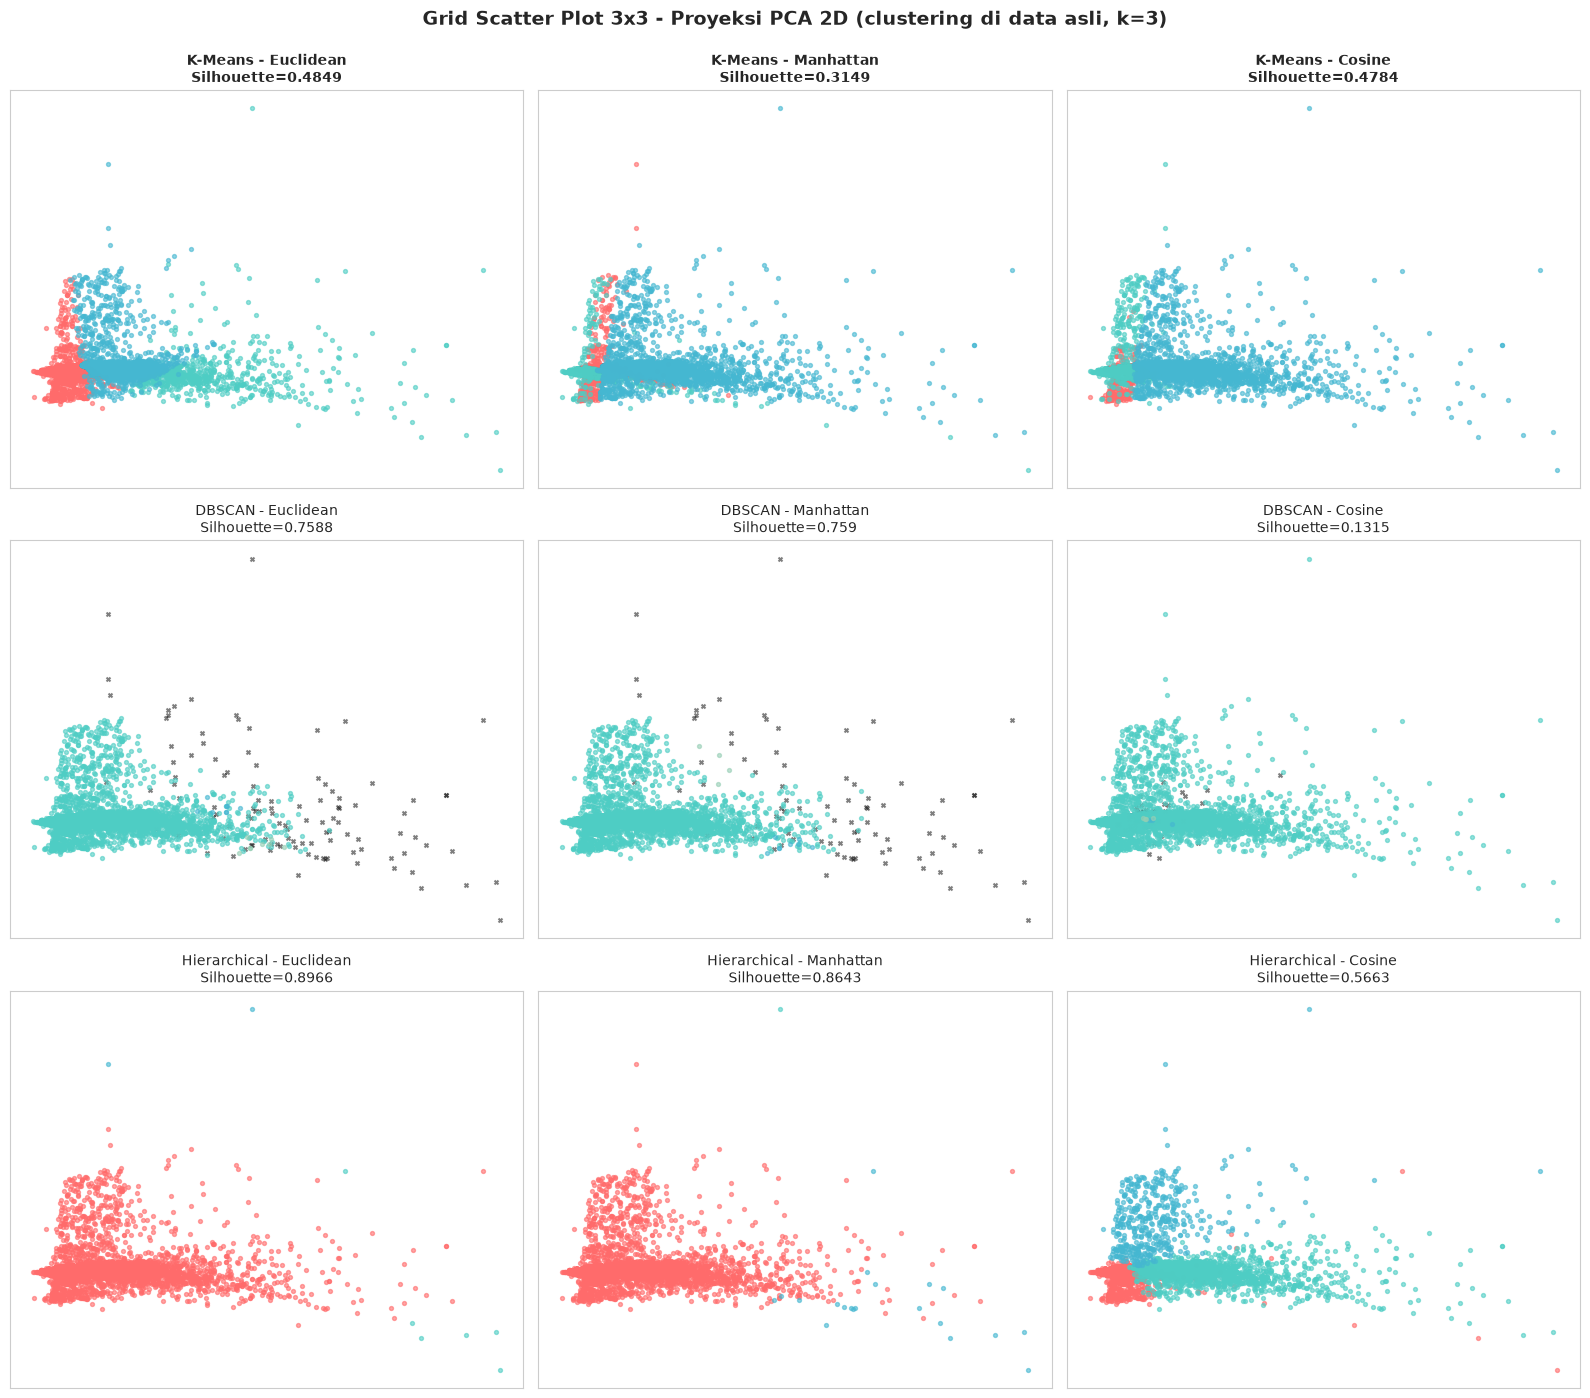

In [5]:
# ============================================
# GRID SCATTER PLOT 3x3 (baris=algoritma, kolom=metrik) - proyeksi PCA 2D
# ============================================
METODE = ['K-Means', 'DBSCAN', 'Hierarchical']
METRIK = ['euclidean', 'manhattan', 'cosine']
WARNA = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']

# Proyeksi PCA 2D dari data ter-scaling (hanya untuk visualisasi)
pca = PCA(n_components=2, random_state=42)
X2d = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for i, m in enumerate(METODE):
    for j, mt in enumerate(METRIK):
        ax = axes[i, j]
        labels = label_semua[(m, mt)]
        unik = sorted(set(labels))
        for idx, lab in enumerate(unik):
            sel = labels == lab
            if lab == -1:
                ax.scatter(X2d[sel, 0], X2d[sel, 1], c='black', marker='x',
                           s=8, alpha=0.5, label='Noise')
            else:
                ax.scatter(X2d[sel, 0], X2d[sel, 1], s=8, alpha=0.6,
                           c=WARNA[idx % len(WARNA)], label=f'C{lab}')
        sil = df_hasil[(df_hasil['Metode']==m) & (df_hasil['Metric']==mt.capitalize())]['Silhouette'].values[0]
        ax.set_title(f'{m} - {mt.capitalize()}\nSilhouette={sil}', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(f'{m} - {mt.capitalize()}\nSilhouette={sil}', fontsize=10, fontweight='bold')

fig.suptitle('Grid Scatter Plot 3x3 - Proyeksi PCA 2D (clustering di data asli, k=3)',
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout(); plt.show()

In [6]:
df_hasil.to_csv('hasil_perbandingan_9_metode.csv', index=False)
print("Disimpan ke 'hasil_perbandingan_9_metode.csv'")

Disimpan ke 'hasil_perbandingan_9_metode.csv'


## Kesimpulan Sementara (Dataset PBL)

* **Semua 9 konfigurasi menghasilkan k=3** -> fair comparison tercapai.
* **Silhouette tertinggi**: lihat tabel (makin besar makin bagus).
* **DBI terkecil**: lihat tabel (makin kecil makin bagus; dihitung Euclidean).
* **ARI/NMI = '-'** karena dataset PBL tidak memiliki label ground truth
  (dihitung pada dataset kontrol di `Dataset_Kontrol.ipynb`).
* DBSCAN satu-satunya yang menghasilkan **noise** (% noise tertera).

Lihat `Dataset_Kontrol.ipynb` untuk validasi pipeline pada data berlabel
(make_blobs & make_moons) di mana ARI/NMI terisi.